# Clustering Overlap and Alternative Methods

## Objective

This follow-up extends the validated team-season profiling workflow without replacing or deleting the existing K-Means, hierarchical, or Gaussian-mixture evidence. It asks whether dimensionality reduction or density-based clustering reveals clearer structure in the same 1,028 team-season observations.

The experimental contract is fixed:

- use only the same 15 final clustering features;
- apply the saved `StandardScaler` before every experiment;
- keep points, wins, and goal outcomes outside cluster construction;
- use performance fields only after clustering for interpretation;
- assess separation, retained information, cluster balance, interpretability, and stakeholder usefulness together;
- leave the saved five-profile K-Means deployment artifacts unchanged unless the evidence supports a clearly better replacement.

Distances, distance margins, and distance ratios are geometric diagnostics. They are not probabilities or confidence scores.

In [1]:
import hashlib
import json
import os
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data/processed/team_season_features_eda.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1_048_576), b""):
            digest.update(block)
    return digest.hexdigest()


def cluster_metrics(matrix, labels, noise_label=None):
    labels = np.asarray(labels)
    mask = np.ones(len(labels), dtype=bool)
    if noise_label is not None:
        mask = labels != noise_label

    assigned_labels = labels[mask]
    unique_labels, counts = np.unique(assigned_labels, return_counts=True)
    n_clusters = len(unique_labels)
    noise_count = int((~mask).sum())
    result = {
        "n_clusters": n_clusters,
        "n_noise": noise_count,
        "noise_percentage": noise_count / len(labels) * 100,
        "largest_cluster_proportion": (
            counts.max() / counts.sum() if counts.size else np.nan
        ),
        "smallest_cluster_size": int(counts.min()) if counts.size else np.nan,
        "cluster_size_balance": (
            counts.min() / counts.max() if counts.size else np.nan
        ),
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
    }

    metrics_are_valid = (
        n_clusters >= 2
        and mask.sum() > n_clusters
        and counts.size > 0
        and counts.min() >= 2
    )
    if metrics_are_valid:
        selected_matrix = matrix[mask]
        result.update(
            {
                "silhouette": silhouette_score(selected_matrix, assigned_labels),
                "davies_bouldin": davies_bouldin_score(
                    selected_matrix, assigned_labels
                ),
                "calinski_harabasz": calinski_harabasz_score(
                    selected_matrix, assigned_labels
                ),
            }
        )
    return result


def estimate_k_distance_elbow(distances):
    # Return a deterministic knee for a sorted, increasing k-distance curve.
    sorted_distances = np.sort(np.asarray(distances, dtype=float))
    x_values = np.linspace(0.0, 1.0, len(sorted_distances))
    value_range = sorted_distances[-1] - sorted_distances[0]
    if value_range == 0:
        return float(sorted_distances[0]), 0
    normalized = (sorted_distances - sorted_distances[0]) / value_range
    chord = normalized[0] + x_values * (normalized[-1] - normalized[0])
    elbow_index = int(np.argmax(chord - normalized))
    return float(sorted_distances[elbow_index]), elbow_index


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data/processed/team_season_features_eda.csv"
MODEL_DIR = PROJECT_ROOT / "models/team_profiling"
OUTPUT_DIR = PROJECT_ROOT / "outputs/team_profiling"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

SCALER_PATH = MODEL_DIR / "team_profile_scaler.joblib"
MODEL_PATH = MODEL_DIR / "team_profile_kmeans.joblib"
FEATURES_PATH = MODEL_DIR / "final_features.json"
PROFILE_NAMES_PATH = MODEL_DIR / "profile_names.json"
protected_artifact_hashes = {
    path.name: sha256(path)
    for path in (SCALER_PATH, MODEL_PATH, FEATURES_PATH, PROFILE_NAMES_PATH)
}
print("Project root resolved successfully.")

Project root resolved successfully.


## 1. Load and validate the existing clustering inputs

The saved scaler, K-Means model, feature order, and profile names are treated as protected final artifacts. This notebook reads them but does not overwrite them. Assertions confirm that the data contains one row per team-season, every feature is present and complete, and no performance outcome enters the clustering matrix.

In [2]:
team_seasons = pd.read_csv(DATA_PATH)
final_features = json.loads(FEATURES_PATH.read_text())
profile_names = json.loads(PROFILE_NAMES_PATH.read_text())
scaler = joblib.load(SCALER_PATH)
final_kmeans = joblib.load(MODEL_PATH)

expected_features = [
    "avg_overall_rating",
    "development_gap",
    "goalkeeper_relative_strength",
    "avg_pace",
    "avg_physical",
    "avg_defence",
    "attack_defence_balance",
    "buildUpPlaySpeed",
    "buildUpPlayPassing",
    "chanceCreationPassing",
    "chanceCreationCrossing",
    "chanceCreationShooting",
    "defencePressure",
    "defenceAggression",
    "defenceTeamWidth",
]
performance_columns = [
    "points_per_match",
    "win_rate",
    "goal_difference_per_match",
]

assert team_seasons.shape[0] == 1028
assert final_features == expected_features
assert not set(performance_columns).intersection(final_features)
assert set(final_features + performance_columns).issubset(team_seasons.columns)
assert team_seasons[final_features].isna().sum().sum() == 0
assert not team_seasons.duplicated(["team_api_id", "season"]).any()
assert list(scaler.feature_names_in_) == final_features
assert final_kmeans.cluster_centers_.shape == (5, len(final_features))

X_original = team_seasons[final_features].copy()
X_scaled = scaler.transform(X_original)
X_scaled_frame = pd.DataFrame(
    X_scaled,
    columns=final_features,
    index=team_seasons.index,
)
original_labels = final_kmeans.predict(X_scaled_frame)
original_metrics = cluster_metrics(X_scaled, original_labels)
original_counts = pd.Series(original_labels).value_counts().sort_index()

input_summary = pd.DataFrame(
    {
        "check": [
            "team-season rows",
            "clustering features",
            "missing clustering values",
            "duplicate team-season keys",
            "performance variables used for clustering",
        ],
        "value": [
            len(team_seasons),
            len(final_features),
            int(team_seasons[final_features].isna().sum().sum()),
            int(team_seasons.duplicated(["team_api_id", "season"]).sum()),
            0,
        ],
    }
)
display(input_summary)
display(pd.DataFrame({"feature": final_features}))

,check,value
0,team-season rows,1028
1,clustering features,15
2,missing clustering values,0
3,duplicate team-season keys,0
4,performance variables used for clustering,0


,feature
0,avg_overall_rating
1,development_gap
2,goalkeeper_relative_strength
3,avg_pace
4,avg_physical
5,avg_defence
6,attack_defence_balance
7,buildUpPlaySpeed
8,buildUpPlayPassing
9,chanceCreationPassing


## 2. Current K-Means profile ambiguity

For each team-season, the distance to all five existing centroids is sorted. The nearest distance describes closeness to the assigned profile; the gap to the second-nearest centroid measures assignment separation. A small margin and a nearest/second-nearest ratio near one identify observations lying between profiles.

There is no domain-supported natural cutoff for “ambiguous.” After inspecting the full distribution, the lower margin decile is used only as a transparent relative review group. It does not turn the distance into probability or confidence.

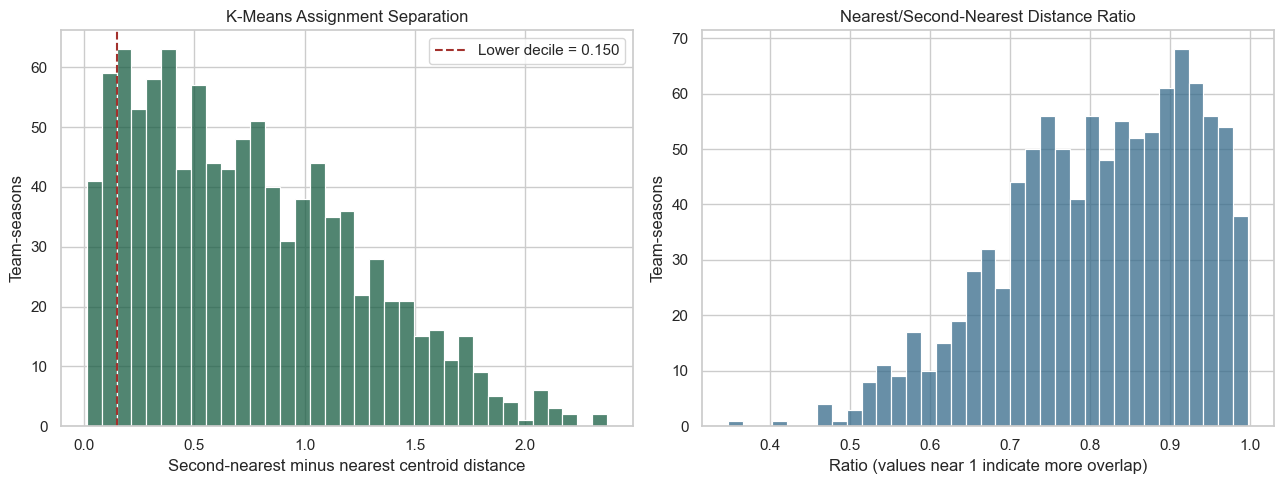

,measure,value
0,median distance margin,0.6697
1,10th percentile distance margin,0.1500
2,90th percentile distance margin,1.4474
3,median nearest/second ratio,0.8246
4,90th percentile nearest/second ratio,0.9582
5,observations in most ambiguous margin decile,103.0000
6,percentage in most ambiguous margin decile,10.0195


,example_type,team_name,season,team_profile,distance_margin,nearest_second_ratio
0,highly ambiguous,Atalanta,2011/2012,Physical Defensive Build-Up,0.0118,0.9948
1,highly ambiguous,FC Schalke 04,2011/2012,High-Pressure Wide Play,0.0131,0.9973
2,highly ambiguous,Córdoba CF,2014/2015,Strong Attack-Oriented Controlled Build-Up,0.0156,0.9954
3,highly ambiguous,Dundee United,2012/2013,Physical Defensive Build-Up,0.0177,0.9953
4,highly ambiguous,1. FC Köln,2014/2015,High-Pressure Wide Play,0.0178,0.9932
5,highly ambiguous,Hamburger SV,2011/2012,Strong Attack-Oriented Controlled Build-Up,0.0219,0.9921
6,highly ambiguous,Hércules Club de Fútbol,2010/2011,Strong Attack-Oriented Controlled Build-Up,0.0238,0.9923
7,highly ambiguous,FC Nantes,2013/2014,Physical Defensive Build-Up,0.0274,0.9883
8,highly ambiguous,Athletic Club de Bilbao,2012/2013,Physical Defensive Build-Up,0.0285,0.9937
9,highly ambiguous,SC Heerenveen,2012/2013,Physical Defensive Build-Up,0.0324,0.9909


In [3]:
centroid_distances = final_kmeans.transform(X_scaled_frame)
centroid_order = np.argsort(centroid_distances, axis=1)
row_positions = np.arange(len(team_seasons))
nearest_clusters = centroid_order[:, 0]
nearest_distances = centroid_distances[row_positions, centroid_order[:, 0]]
second_distances = centroid_distances[row_positions, centroid_order[:, 1]]
distance_margins = second_distances - nearest_distances
distance_ratios = nearest_distances / second_distances

assert np.array_equal(nearest_clusters, original_labels)
assert np.all(distance_margins >= 0)
assert np.all((distance_ratios >= 0) & (distance_ratios <= 1))

margin_p10 = float(np.quantile(distance_margins, 0.10))
margin_p90 = float(np.quantile(distance_margins, 0.90))

ambiguity = team_seasons[
    ["team_api_id", "team_name", "league_name", "season"]
].copy()
ambiguity["kmeans_cluster"] = original_labels
ambiguity["team_profile"] = [profile_names[str(label)] for label in original_labels]
ambiguity["nearest_centroid_distance"] = nearest_distances
ambiguity["second_nearest_centroid_distance"] = second_distances
ambiguity["distance_margin"] = distance_margins
ambiguity["nearest_second_ratio"] = distance_ratios
ambiguity["relative_ambiguity_group"] = np.select(
    [distance_margins <= margin_p10, distance_margins >= margin_p90],
    ["most ambiguous margin decile", "clearest margin decile"],
    default="middle 80%",
)
ambiguity.to_csv(
    TABLES_DIR / "team_profile_assignment_ambiguity.csv",
    index=False,
)

ambiguity_summary = pd.DataFrame(
    {
        "measure": [
            "median distance margin",
            "10th percentile distance margin",
            "90th percentile distance margin",
            "median nearest/second ratio",
            "90th percentile nearest/second ratio",
            "observations in most ambiguous margin decile",
            "percentage in most ambiguous margin decile",
        ],
        "value": [
            np.median(distance_margins),
            margin_p10,
            margin_p90,
            np.median(distance_ratios),
            np.quantile(distance_ratios, 0.90),
            (distance_margins <= margin_p10).sum(),
            (distance_margins <= margin_p10).mean() * 100,
        ],
    }
)
ambiguity_summary.to_csv(
    TABLES_DIR / "team_profile_assignment_ambiguity_summary.csv",
    index=False,
)

ambiguous_examples = ambiguity.nsmallest(10, "distance_margin").assign(
    example_type="highly ambiguous"
)
clear_examples = ambiguity.nlargest(10, "distance_margin").assign(
    example_type="clearly separated"
)
ambiguity_examples = pd.concat(
    [ambiguous_examples, clear_examples],
    ignore_index=True,
)
ambiguity_examples.to_csv(
    TABLES_DIR / "team_profile_ambiguity_examples.csv",
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(distance_margins, bins=35, ax=axes[0], color="#175c42")
axes[0].axvline(
    margin_p10,
    color="#a3312d",
    linestyle="--",
    label=f"Lower decile = {margin_p10:.3f}",
)
axes[0].set(
    title="K-Means Assignment Separation",
    xlabel="Second-nearest minus nearest centroid distance",
    ylabel="Team-seasons",
)
axes[0].legend()
sns.histplot(distance_ratios, bins=35, ax=axes[1], color="#356a8a")
axes[1].set(
    title="Nearest/Second-Nearest Distance Ratio",
    xlabel="Ratio (values near 1 indicate more overlap)",
    ylabel="Team-seasons",
)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "team_profile_assignment_ambiguity.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

display(ambiguity_summary.round(4))
display(ambiguity_examples[
    [
        "example_type",
        "team_name",
        "season",
        "team_profile",
        "distance_margin",
        "nearest_second_ratio",
    ]
].round(4))

## 3. PCA explained variance and loadings

PCA is fitted after standardization and only on the 15 approved clustering features. The scree and cumulative-variance evidence quantify the information retained at each dimensionality. Component loadings are saved so any football interpretation is grounded in the observed coefficients; component signs themselves are arbitrary.

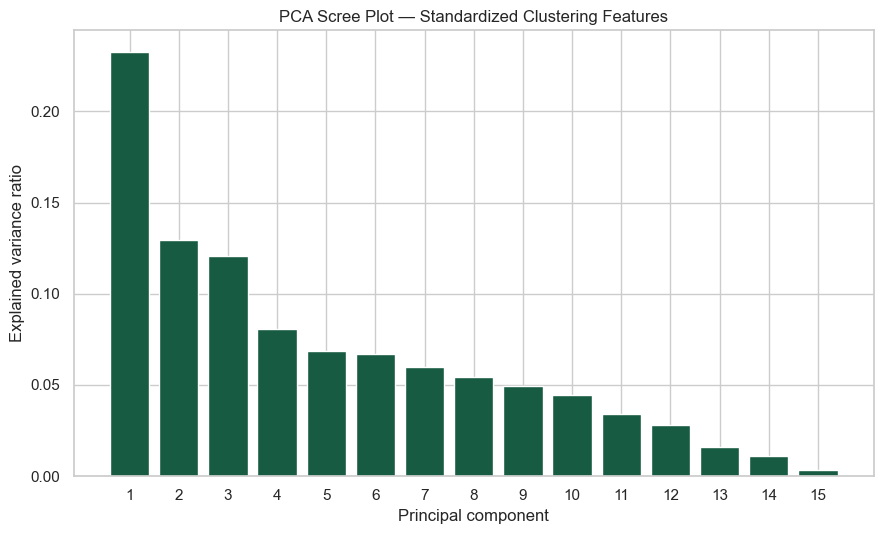

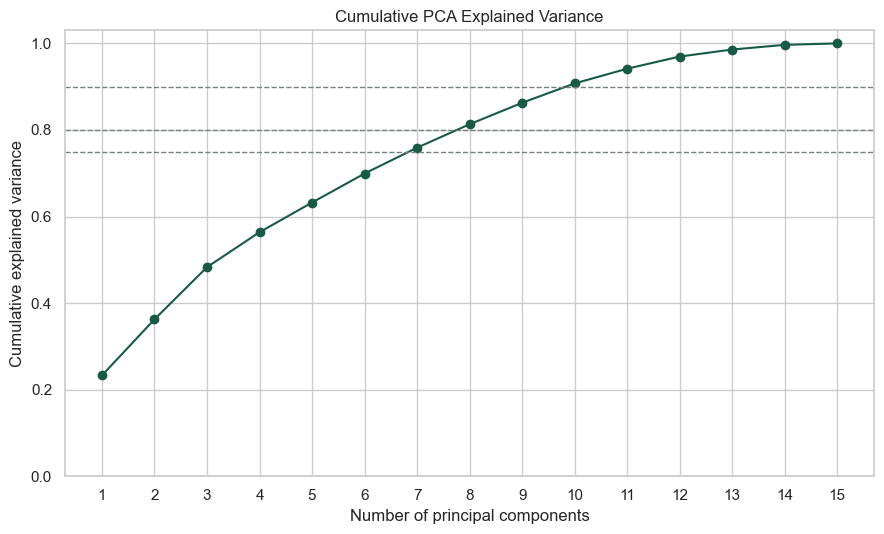

,principal_component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.2327,0.2327
1,PC2,0.1297,0.3624
2,PC3,0.1206,0.4830
3,PC4,0.0808,0.5638
4,PC5,0.0685,0.6323
5,PC6,0.0670,0.6993
6,PC7,0.0597,0.7590
7,PC8,0.0542,0.8132
8,PC9,0.0496,0.8628
9,PC10,0.0448,0.9075


,feature,PC1,PC2
0,avg_overall_rating,0.5011,-0.0916
1,development_gap,-0.1098,0.3168
2,goalkeeper_relative_strength,0.0190,-0.0889
3,avg_pace,0.4323,0.0899
4,avg_physical,0.4772,-0.1809
5,avg_defence,0.4545,-0.2465
6,attack_defence_balance,0.1009,0.3082
7,buildUpPlaySpeed,0.0712,-0.1297
8,buildUpPlayPassing,-0.0814,-0.1983
9,chanceCreationPassing,0.1193,0.0793


**Loading-based reading.** PC1 is led by `avg_overall_rating`, `avg_physical`, `avg_defence`, and `avg_pace`; their same-direction loadings make PC1 primarily a broad squad-quality/physical dimension. PC2 is led by `defencePressure`, `defenceTeamWidth`, `development_gap`, and `attack_defence_balance`, so it is more accurately described as a defensive-pressure/width and development-balance contrast than as a single football trait.

In [4]:
pca_full = PCA(n_components=len(final_features), random_state=RANDOM_STATE)
X_pca_full = pca_full.fit_transform(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
component_names = [f"PC{number}" for number in range(1, len(final_features) + 1)]

pca_variance = pd.DataFrame(
    {
        "principal_component": component_names,
        "explained_variance_ratio": pca_full.explained_variance_ratio_,
        "cumulative_explained_variance": cumulative_variance,
    }
)
pca_variance.to_csv(
    TABLES_DIR / "pca_explained_variance.csv",
    index=False,
)

pca_loadings = pd.DataFrame(
    pca_full.components_.T,
    index=final_features,
    columns=component_names,
).rename_axis("feature").reset_index()
pca_loadings.to_csv(TABLES_DIR / "pca_loadings.csv", index=False)

fig, axis = plt.subplots(figsize=(9, 5.5))
axis.bar(
    range(1, len(final_features) + 1),
    pca_full.explained_variance_ratio_,
    color="#175c42",
)
axis.set(
    title="PCA Scree Plot — Standardized Clustering Features",
    xlabel="Principal component",
    ylabel="Explained variance ratio",
    xticks=range(1, len(final_features) + 1),
)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "pca_scree_plot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

fig, axis = plt.subplots(figsize=(9, 5.5))
axis.plot(
    range(1, len(final_features) + 1),
    cumulative_variance,
    marker="o",
    color="#175c42",
)
for threshold in (0.75, 0.80, 0.90):
    axis.axhline(threshold, color="#75827d", linestyle="--", linewidth=1)
axis.set(
    title="Cumulative PCA Explained Variance",
    xlabel="Number of principal components",
    ylabel="Cumulative explained variance",
    xticks=range(1, len(final_features) + 1),
    ylim=(0, 1.03),
)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "pca_cumulative_explained_variance.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

pc1_ranked = pca_loadings.set_index("feature")["PC1"].abs().sort_values(ascending=False)
pc2_ranked = pca_loadings.set_index("feature")["PC2"].abs().sort_values(ascending=False)
display(pca_variance.round(4))
display(pca_loadings[["feature", "PC1", "PC2"]].round(4))
display(Markdown(
    f"**Loading-based reading.** PC1 is led by `{pc1_ranked.index[0]}`, "
    f"`{pc1_ranked.index[1]}`, `{pc1_ranked.index[2]}`, and `{pc1_ranked.index[3]}`; "
    "their same-direction loadings make PC1 primarily a broad squad-quality/physical dimension. "
    f"PC2 is led by `{pc2_ranked.index[0]}`, `{pc2_ranked.index[1]}`, "
    f"`{pc2_ranked.index[2]}`, and `{pc2_ranked.index[3]}`, so it is more accurately "
    "described as a defensive-pressure/width and development-balance contrast than as a single football trait."
))

## 4. Two-dimensional PCA view of the existing profiles

PC1 and PC2 are used only as a visualization surface. Their cumulative explained variance is reported on the plot; the figure is not evidence that two dimensions contain the complete cluster structure.

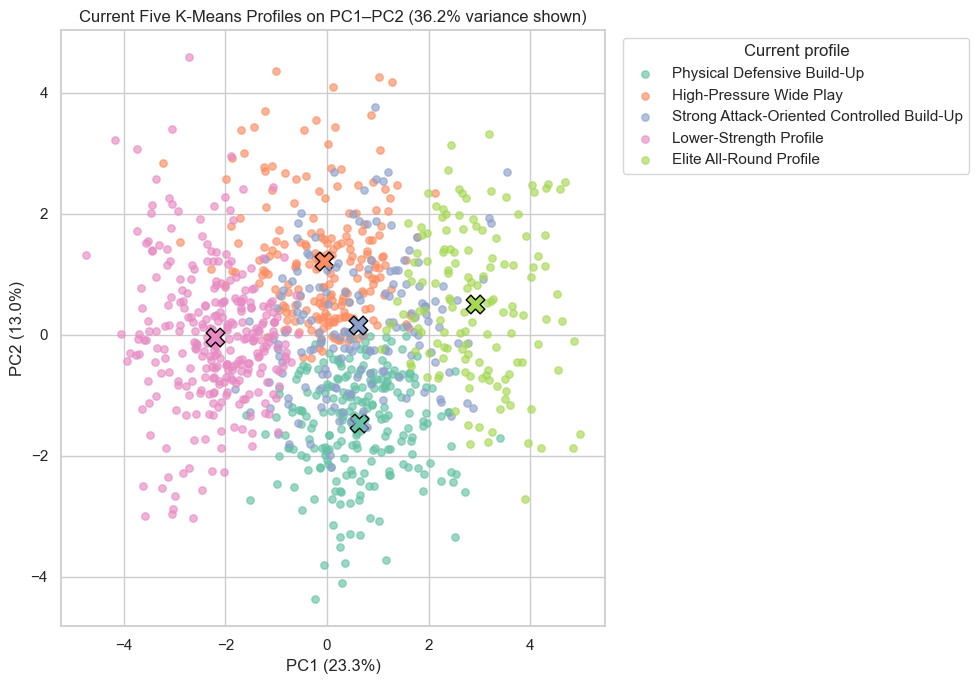

In [5]:
current_centres_pca = pca_full.transform(final_kmeans.cluster_centers_)

fig, axis = plt.subplots(figsize=(10, 7))
palette = sns.color_palette("Set2", n_colors=5)
for cluster in range(5):
    selected = original_labels == cluster
    axis.scatter(
        X_pca_full[selected, 0],
        X_pca_full[selected, 1],
        s=28,
        alpha=0.65,
        color=palette[cluster],
        label=profile_names[str(cluster)],
    )
    axis.scatter(
        current_centres_pca[cluster, 0],
        current_centres_pca[cluster, 1],
        marker="X",
        s=180,
        color=palette[cluster],
        edgecolor="black",
        linewidth=1,
    )
axis.set(
    title=(
        "Current Five K-Means Profiles on PC1–PC2 "
        f"({cumulative_variance[1] * 100:.1f}% variance shown)"
    ),
    xlabel=f"PC1 ({pca_full.explained_variance_ratio_[0] * 100:.1f}%)",
    ylabel=f"PC2 ({pca_full.explained_variance_ratio_[1] * 100:.1f}%)",
)
axis.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Current profile")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "pca_current_kmeans_clusters.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 5. PCA + K-Means search

The search tests the requested component counts and `k=2…10`. Metrics are computed in each reduced PCA space and accompanied by explained variance and cluster-size balance.

Selection is deliberately not “maximum silhouette wins.” Two-dimensional solutions are informative visual summaries but retain only a minority of total variance. A reportable candidate must retain at least 75% variance, provide four to six useful profiles, and avoid very small groups. If a five-profile solution lies within 0.01 silhouette of the strongest eligible four-to-six-profile option, five profiles are preferred for direct comparison with the established business segmentation.

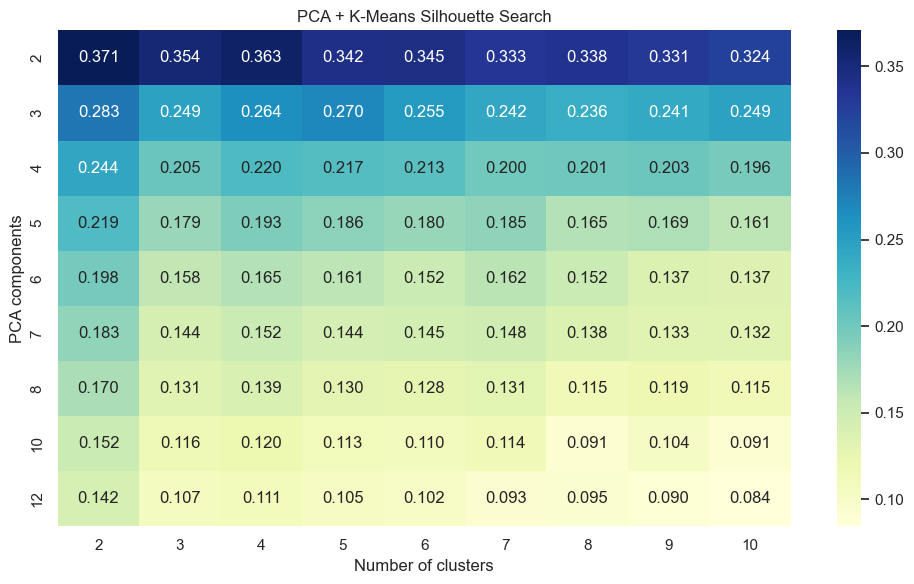

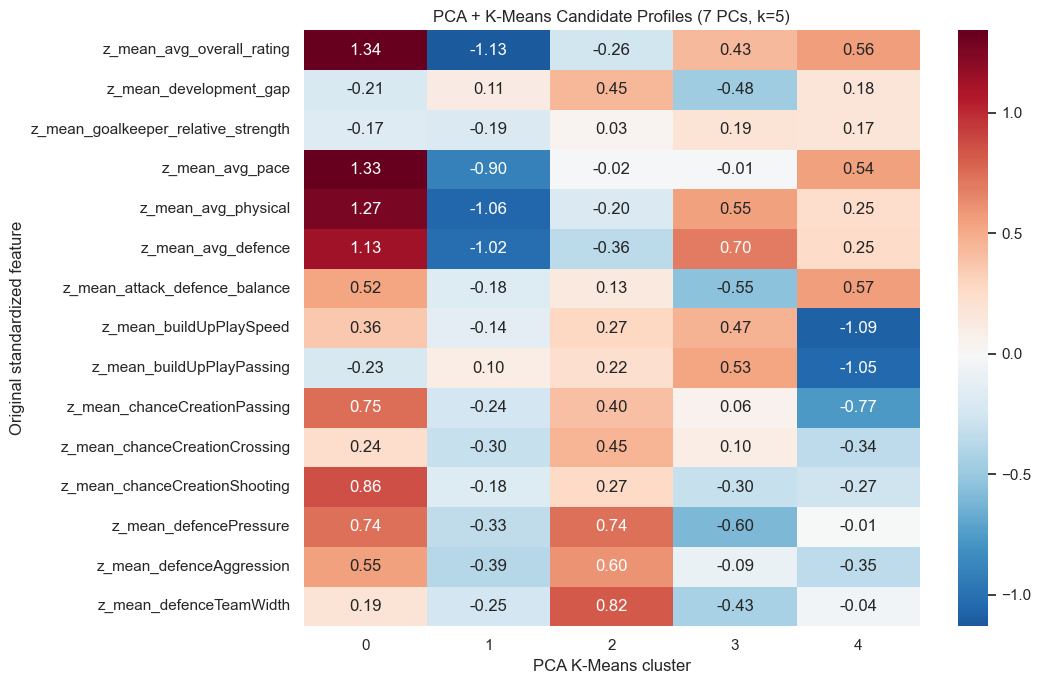

,n_components,n_clusters,explained_variance_retained,silhouette,davies_bouldin,calinski_harabasz,inertia,cluster_size_balance,largest_cluster_proportion,smallest_cluster_size
0,2,2,0.3624,0.3709,1.0188,747.1534,3233.6220,0.8099,0.5525,460
2,2,4,0.3624,0.3630,0.8773,758.7368,1734.0053,0.6678,0.2899,199
1,2,3,0.3624,0.3540,0.9866,720.8129,2322.2491,0.6764,0.3998,278
4,2,6,0.3624,0.3448,0.8988,702.0980,1260.1324,0.3849,0.2451,97
3,2,5,0.3624,0.3420,0.9120,710.9468,1478.4928,0.4330,0.2539,113
6,2,8,0.3624,0.3381,0.8314,714.4046,946.7687,0.4486,0.1800,83
5,2,7,0.3624,0.3334,0.9034,708.4523,1082.3361,0.3796,0.2101,82
7,2,9,0.3624,0.3306,0.8687,695.6347,864.9031,0.2414,0.1693,42
8,2,10,0.3624,0.3235,0.8836,689.2312,787.8489,0.3520,0.1741,63
9,3,2,0.4830,0.2828,1.3142,475.0362,5090.7308,0.8067,0.5535,459


,n_components,n_clusters,explained_variance_retained,silhouette,davies_bouldin,calinski_harabasz,inertia,cluster_size_balance,largest_cluster_proportion,smallest_cluster_size,original_space_silhouette_for_labels,original_space_davies_bouldin_for_labels,original_space_calinski_harabasz_for_labels,adjusted_rand_index_vs_current_kmeans,selection_reason
0,7.0,5.0,0.759,0.1443,1.7136,162.8428,7150.6547,0.4762,0.286,140.0,0.1007,2.1596,107.6439,0.9304,The five-profile option is within 0.01 silhoue...


,pca_cluster,team_seasons,mapped_current_profile,z_mean_avg_overall_rating,z_mean_development_gap,z_mean_goalkeeper_relative_strength,z_mean_avg_pace,z_mean_avg_physical,z_mean_avg_defence,z_mean_attack_defence_balance,...,z_mean_buildUpPlayPassing,z_mean_chanceCreationPassing,z_mean_chanceCreationCrossing,z_mean_chanceCreationShooting,z_mean_defencePressure,z_mean_defenceAggression,z_mean_defenceTeamWidth,interpretation_only_mean_points_per_match,interpretation_only_mean_win_rate,interpretation_only_mean_goal_difference_per_match
0,0,140,Elite All-Round Profile,1.342,-0.212,-0.171,1.330,1.268,1.130,0.522,...,-0.226,0.745,0.245,0.862,0.741,0.546,0.191,1.866,0.547,0.756
1,1,294,Lower-Strength Profile,-1.132,0.108,-0.186,-0.904,-1.061,-1.017,-0.185,...,0.098,-0.244,-0.305,-0.183,-0.333,-0.386,-0.248,1.153,0.297,-0.350
2,2,191,High-Pressure Wide Play,-0.256,0.451,0.033,-0.020,-0.201,-0.360,0.126,...,0.224,0.402,0.454,0.266,0.741,0.602,0.824,1.369,0.373,-0.004
3,3,243,Physical Defensive Build-Up,0.426,-0.480,0.187,-0.014,0.548,0.697,-0.551,...,0.526,0.058,0.097,-0.305,-0.601,-0.089,-0.429,1.252,0.329,-0.183
4,4,160,Strong Attack-Oriented Controlled Build-Up,0.564,0.177,0.168,0.543,0.247,0.251,0.569,...,-1.047,-0.771,-0.343,-0.273,-0.010,-0.352,-0.043,1.525,0.426,0.248


**PCA candidate.** The strongest raw result is 2 PCs with k=2, but it retains only 36.2% variance. The reportable comparator uses 7 PCs and k=5, retaining 75.9% variance. The five-profile option is within 0.01 silhouette of the strongest eligible four-to-six-profile solution and preserves comparable stakeholder granularity. Its Adjusted Rand Index against the existing labels is 0.930.

In [6]:
component_candidates = [2, 3, 4, 5, 6, 7, 8, 10, 12]
pca_kmeans_rows = []

for n_components in component_candidates:
    reduced = X_pca_full[:, :n_components]
    variance_retained = cumulative_variance[n_components - 1]
    for n_clusters in range(2, 11):
        model = KMeans(
            n_clusters=n_clusters,
            n_init=20,
            random_state=RANDOM_STATE,
        )
        labels = model.fit_predict(reduced)
        metrics = cluster_metrics(reduced, labels)
        pca_kmeans_rows.append(
            {
                "n_components": n_components,
                "n_clusters": n_clusters,
                "explained_variance_retained": variance_retained,
                "silhouette": metrics["silhouette"],
                "davies_bouldin": metrics["davies_bouldin"],
                "calinski_harabasz": metrics["calinski_harabasz"],
                "inertia": model.inertia_,
                "cluster_size_balance": metrics["cluster_size_balance"],
                "largest_cluster_proportion": metrics[
                    "largest_cluster_proportion"
                ],
                "smallest_cluster_size": metrics["smallest_cluster_size"],
            }
        )

pca_kmeans_results = pd.DataFrame(pca_kmeans_rows)
pca_kmeans_results.to_csv(
    TABLES_DIR / "pca_kmeans_search_results.csv",
    index=False,
)

fig, axis = plt.subplots(figsize=(10, 6))
sns.heatmap(
    pca_kmeans_results.pivot(
        index="n_components",
        columns="n_clusters",
        values="silhouette",
    ),
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    ax=axis,
)
axis.set_title("PCA + K-Means Silhouette Search")
axis.set_xlabel("Number of clusters")
axis.set_ylabel("PCA components")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "pca_kmeans_search_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

highest_native_row = pca_kmeans_results.sort_values(
    ["silhouette", "cluster_size_balance"],
    ascending=[False, False],
).iloc[0]

eligible_pca = pca_kmeans_results[
    (pca_kmeans_results["explained_variance_retained"] >= 0.75)
    & (pca_kmeans_results["n_clusters"].between(4, 6))
].copy()
best_eligible_row = eligible_pca.sort_values(
    ["silhouette", "cluster_size_balance"],
    ascending=[False, False],
).iloc[0]
best_five_profile_row = eligible_pca[
    eligible_pca["n_clusters"] == 5
].sort_values(
    ["silhouette", "cluster_size_balance"],
    ascending=[False, False],
).iloc[0]

if (
    best_eligible_row["silhouette"]
    - best_five_profile_row["silhouette"]
    <= 0.01
):
    selected_pca_row = best_five_profile_row
    pca_selection_reason = (
        "The five-profile option is within 0.01 silhouette of the strongest "
        "eligible four-to-six-profile solution and preserves comparable "
        "stakeholder granularity."
    )
else:
    selected_pca_row = best_eligible_row
    pca_selection_reason = (
        "The strongest eligible configuration improves separation by more than "
        "the declared practical tolerance."
    )

selected_pca_components = int(selected_pca_row["n_components"])
selected_pca_clusters = int(selected_pca_row["n_clusters"])
X_selected_pca = X_pca_full[:, :selected_pca_components]
selected_pca_kmeans = KMeans(
    n_clusters=selected_pca_clusters,
    n_init=20,
    random_state=RANDOM_STATE,
)
selected_pca_labels = selected_pca_kmeans.fit_predict(X_selected_pca)
selected_pca_original_space_metrics = cluster_metrics(
    X_scaled,
    selected_pca_labels,
)
selected_pca_ari = adjusted_rand_score(original_labels, selected_pca_labels)

contingency = pd.crosstab(
    pd.Series(selected_pca_labels, name="pca_cluster"),
    pd.Series(original_labels, name="original_cluster"),
)
row_indices, column_indices = linear_sum_assignment(-contingency.to_numpy())
pca_to_original = {
    int(contingency.index[row]): int(contingency.columns[column])
    for row, column in zip(row_indices, column_indices)
}

standardized_profiles = (
    X_scaled_frame.assign(pca_cluster=selected_pca_labels)
    .groupby("pca_cluster")
    .mean()
    .add_prefix("z_mean_")
)
performance_profiles = (
    team_seasons.assign(pca_cluster=selected_pca_labels)
    .groupby("pca_cluster")[performance_columns]
    .mean()
    .add_prefix("interpretation_only_mean_")
)
pca_candidate_profiles = standardized_profiles.join(performance_profiles)
pca_candidate_profiles.insert(
    0,
    "mapped_current_profile",
    [profile_names[str(pca_to_original[index])] for index in pca_candidate_profiles.index],
)
pca_candidate_profiles.insert(
    0,
    "team_seasons",
    pd.Series(selected_pca_labels).value_counts().sort_index(),
)
pca_candidate_profiles.reset_index().to_csv(
    TABLES_DIR / "pca_kmeans_candidate_cluster_profiles.csv",
    index=False,
)

pca_candidate_summary = pd.DataFrame(
    [
        {
            **selected_pca_row.to_dict(),
            "original_space_silhouette_for_labels": (
                selected_pca_original_space_metrics["silhouette"]
            ),
            "original_space_davies_bouldin_for_labels": (
                selected_pca_original_space_metrics["davies_bouldin"]
            ),
            "original_space_calinski_harabasz_for_labels": (
                selected_pca_original_space_metrics["calinski_harabasz"]
            ),
            "adjusted_rand_index_vs_current_kmeans": selected_pca_ari,
            "selection_reason": pca_selection_reason,
        }
    ]
)
pca_candidate_summary.to_csv(
    TABLES_DIR / "pca_kmeans_candidate_summary.csv",
    index=False,
)

fig, axis = plt.subplots(figsize=(11, 7))
profile_heatmap = standardized_profiles.T
sns.heatmap(
    profile_heatmap,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axis,
)
axis.set_title(
    f"PCA + K-Means Candidate Profiles ({selected_pca_components} PCs, "
    f"k={selected_pca_clusters})"
)
axis.set_xlabel("PCA K-Means cluster")
axis.set_ylabel("Original standardized feature")
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "pca_kmeans_candidate_profile_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

display(pca_kmeans_results.sort_values("silhouette", ascending=False).head(12).round(4))
display(pca_candidate_summary.round(4))
display(pca_candidate_profiles.reset_index().round(3))
display(Markdown(
    f"**PCA candidate.** The strongest raw result is {int(highest_native_row['n_components'])} "
    f"PCs with k={int(highest_native_row['n_clusters'])}, but it retains only "
    f"{highest_native_row['explained_variance_retained'] * 100:.1f}% variance. "
    f"The reportable comparator uses {selected_pca_components} PCs and "
    f"k={selected_pca_clusters}, retaining "
    f"{selected_pca_row['explained_variance_retained'] * 100:.1f}% variance. "
    f"{pca_selection_reason} Its Adjusted Rand Index against the existing labels is "
    f"{selected_pca_ari:.3f}."
))

## 6. DBSCAN on the standardized 15-feature space

The distance to the `min_samples`-th neighbour is inspected for each requested neighbourhood size. A deterministic geometric knee on each sorted curve provides the centre of a small epsilon grid; epsilon is therefore tied to observed neighbour distances rather than chosen randomly.

For density methods, separation metrics exclude noise and are recorded only when at least two non-noise clusters exist and every scored cluster contains at least two observations. A deliberately generous usability screen requires at least two clusters, no more than 50% noise, no cluster containing more than 90% of assigned rows, and every cluster containing at least 2% of the 1,028 observations. This screen diagnoses whether DBSCAN produces stakeholder-usable profiles; it does not tune a final model.

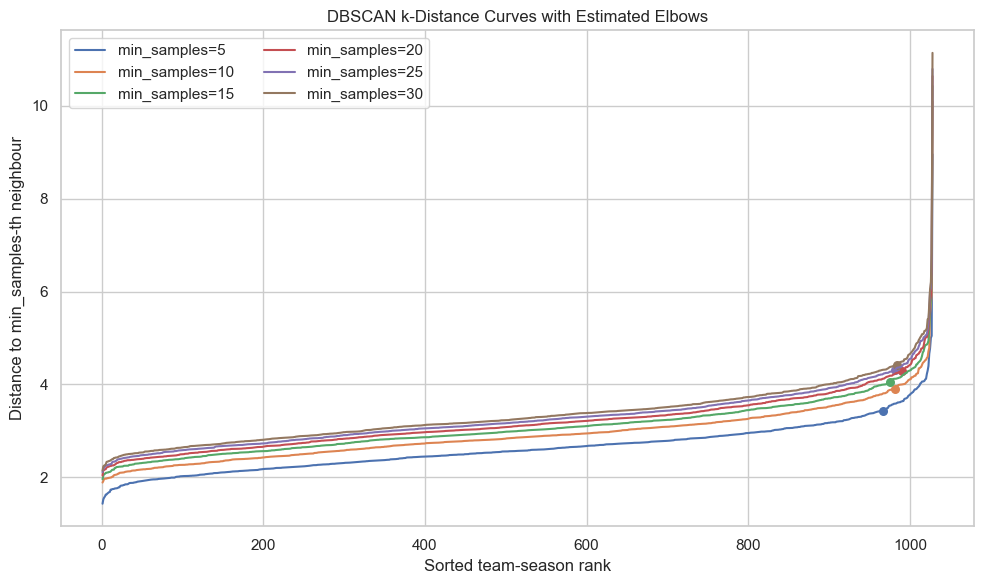

,min_samples,estimated_elbow_eps,elbow_observation_rank,elbow_percentile
0,5,3.4332,967,94.0661
1,10,3.9037,982,95.5253
2,15,4.0432,976,94.9416
3,20,4.2878,990,96.3035
4,25,4.3110,982,95.5253
5,30,4.4274,984,95.7198


,eps,min_samples,elbow_eps,eps_multiplier,n_clusters,n_noise,noise_percentage,largest_cluster_proportion,smallest_cluster_size,cluster_size_balance,silhouette,davies_bouldin,calinski_harabasz,passes_generous_usability_screen
4,3.2616,5,3.4332,0.95,2,38,3.6965,0.9960,4,0.0041,0.3215,0.8308,12.3176,False
3,3.0899,5,3.4332,0.90,2,64,6.2257,0.9948,5,0.0052,0.3128,0.8848,14.5447,False
5,3.4332,5,3.4332,1.00,2,23,2.2374,0.9950,5,0.0050,0.3046,0.9154,13.9380,False
0,2.4033,5,3.4332,0.70,4,431,41.9261,0.9682,5,0.0087,0.0548,1.1848,11.0636,False
1,2.5749,5,3.4332,0.75,3,279,27.1401,0.9826,6,0.0082,0.0374,1.3387,8.3894,False


,cluster,team_seasons,label_type
0,-1,38,noise
1,0,986,cluster
2,1,4,cluster


**DBSCAN finding.** No usable configuration; highest-silhouette diagnostic only. The recorded diagnostic uses `eps=3.2616` and `min_samples=5`. It finds 2 non-noise clusters and marks 3.7% as noise, but the largest cluster contains 99.6% of assigned observations and the smallest contains only 4.

In [7]:
dbscan_min_samples = [5, 10, 15, 20, 25, 30]
eps_multipliers = [0.70, 0.75, 0.80, 0.90, 0.95, 1.00, 1.05, 1.10]
k_distance_curves = {}
k_distance_rows = []

for min_samples in dbscan_min_samples:
    neighbour_distances = NearestNeighbors(
        n_neighbors=min_samples
    ).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]
    elbow_eps, elbow_index = estimate_k_distance_elbow(neighbour_distances)
    sorted_distances = np.sort(neighbour_distances)
    k_distance_curves[min_samples] = sorted_distances
    k_distance_rows.append(
        {
            "min_samples": min_samples,
            "estimated_elbow_eps": elbow_eps,
            "elbow_observation_rank": elbow_index + 1,
            "elbow_percentile": (elbow_index + 1) / len(sorted_distances) * 100,
        }
    )

k_distance_elbows = pd.DataFrame(k_distance_rows)
k_distance_elbows.to_csv(
    TABLES_DIR / "dbscan_k_distance_elbows.csv",
    index=False,
)

fig, axis = plt.subplots(figsize=(10, 6))
for row in k_distance_rows:
    min_samples = int(row["min_samples"])
    values = k_distance_curves[min_samples]
    axis.plot(
        np.arange(1, len(values) + 1),
        values,
        label=f"min_samples={min_samples}",
    )
    axis.scatter(
        row["elbow_observation_rank"],
        row["estimated_elbow_eps"],
        s=30,
    )
axis.set(
    title="DBSCAN k-Distance Curves with Estimated Elbows",
    xlabel="Sorted team-season rank",
    ylabel="Distance to min_samples-th neighbour",
)
axis.legend(ncol=2)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "dbscan_k_distance_plot.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

dbscan_rows = []
for elbow in k_distance_rows:
    min_samples = int(elbow["min_samples"])
    base_eps = float(elbow["estimated_elbow_eps"])
    for multiplier in eps_multipliers:
        eps = base_eps * multiplier
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        dbscan_rows.append(
            {
                "eps": eps,
                "min_samples": min_samples,
                "elbow_eps": base_eps,
                "eps_multiplier": multiplier,
                **cluster_metrics(X_scaled, labels, noise_label=-1),
            }
        )

dbscan_results = pd.DataFrame(dbscan_rows)
minimum_profile_size = int(np.ceil(len(team_seasons) * 0.02))
dbscan_results["passes_generous_usability_screen"] = (
    (dbscan_results["n_clusters"] >= 2)
    & (dbscan_results["noise_percentage"] <= 50)
    & (dbscan_results["largest_cluster_proportion"] <= 0.90)
    & (dbscan_results["smallest_cluster_size"] >= minimum_profile_size)
)
dbscan_results.to_csv(
    TABLES_DIR / "dbscan_search_results.csv",
    index=False,
)

valid_dbscan = dbscan_results.dropna(subset=["silhouette"])
usable_dbscan = valid_dbscan[
    valid_dbscan["passes_generous_usability_screen"]
]
if usable_dbscan.empty:
    selected_dbscan_row = valid_dbscan.sort_values(
        ["silhouette", "noise_percentage"],
        ascending=[False, True],
    ).iloc[0]
    dbscan_status = "No usable configuration; highest-silhouette diagnostic only"
else:
    selected_dbscan_row = usable_dbscan.sort_values(
        ["silhouette", "noise_percentage", "cluster_size_balance"],
        ascending=[False, True, False],
    ).iloc[0]
    dbscan_status = "Best configuration passing usability screen"

selected_dbscan_labels = DBSCAN(
    eps=float(selected_dbscan_row["eps"]),
    min_samples=int(selected_dbscan_row["min_samples"]),
).fit_predict(X_scaled)
dbscan_candidate_sizes = (
    pd.Series(selected_dbscan_labels)
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="team_seasons")
)
dbscan_candidate_sizes["label_type"] = np.where(
    dbscan_candidate_sizes["cluster"] == -1,
    "noise",
    "cluster",
)
dbscan_candidate_sizes.to_csv(
    TABLES_DIR / "dbscan_candidate_cluster_sizes.csv",
    index=False,
)

display(k_distance_elbows.round(4))
display(valid_dbscan.sort_values("silhouette", ascending=False).head(12).round(4))
display(dbscan_candidate_sizes)
display(Markdown(
    f"**DBSCAN finding.** {dbscan_status}. The recorded diagnostic uses "
    f"`eps={selected_dbscan_row['eps']:.4f}` and "
    f"`min_samples={int(selected_dbscan_row['min_samples'])}`. It finds "
    f"{int(selected_dbscan_row['n_clusters'])} non-noise clusters and marks "
    f"{selected_dbscan_row['noise_percentage']:.1f}% as noise, but the largest "
    f"cluster contains {selected_dbscan_row['largest_cluster_proportion'] * 100:.1f}% "
    f"of assigned observations and the smallest contains only "
    f"{int(selected_dbscan_row['smallest_cluster_size'])}."
))

## 7. Limited PCA + DBSCAN check

Because plain DBSCAN may struggle in 15 dimensions, a limited follow-up tests 5, 6, 8, and 10 PCA components with neighbourhood sizes 5, 10, 15, and 20. Each PCA/minimum-neighbour pair receives only five epsilon values around its own k-distance elbow. The same usability screen is applied.

In [8]:
pca_dbscan_rows = []
for n_components in [5, 6, 8, 10]:
    reduced = X_pca_full[:, :n_components]
    variance_retained = cumulative_variance[n_components - 1]
    for min_samples in [5, 10, 15, 20]:
        neighbour_distances = NearestNeighbors(
            n_neighbors=min_samples
        ).fit(reduced).kneighbors(reduced)[0][:, -1]
        base_eps, elbow_index = estimate_k_distance_elbow(neighbour_distances)
        for multiplier in [0.80, 0.90, 1.00, 1.10, 1.20]:
            eps = base_eps * multiplier
            labels = DBSCAN(
                eps=eps,
                min_samples=min_samples,
            ).fit_predict(reduced)
            pca_dbscan_rows.append(
                {
                    "n_components": n_components,
                    "explained_variance_retained": variance_retained,
                    "eps": eps,
                    "min_samples": min_samples,
                    "elbow_eps": base_eps,
                    "eps_multiplier": multiplier,
                    **cluster_metrics(reduced, labels, noise_label=-1),
                }
            )

pca_dbscan_results = pd.DataFrame(pca_dbscan_rows)
pca_dbscan_results["passes_generous_usability_screen"] = (
    (pca_dbscan_results["n_clusters"] >= 2)
    & (pca_dbscan_results["noise_percentage"] <= 50)
    & (pca_dbscan_results["largest_cluster_proportion"] <= 0.90)
    & (pca_dbscan_results["smallest_cluster_size"] >= minimum_profile_size)
)
pca_dbscan_results.to_csv(
    TABLES_DIR / "pca_dbscan_search_results.csv",
    index=False,
)

valid_pca_dbscan = pca_dbscan_results.dropna(subset=["silhouette"])
usable_pca_dbscan = valid_pca_dbscan[
    valid_pca_dbscan["passes_generous_usability_screen"]
]
if usable_pca_dbscan.empty:
    selected_pca_dbscan_row = valid_pca_dbscan.sort_values(
        ["silhouette", "noise_percentage"],
        ascending=[False, True],
    ).iloc[0]
    pca_dbscan_status = (
        "No usable configuration; highest-silhouette diagnostic only"
    )
else:
    selected_pca_dbscan_row = usable_pca_dbscan.sort_values(
        ["silhouette", "noise_percentage", "cluster_size_balance"],
        ascending=[False, True, False],
    ).iloc[0]
    pca_dbscan_status = "Best configuration passing usability screen"

selected_pca_dbscan_matrix = X_pca_full[
    :, :int(selected_pca_dbscan_row["n_components"])
]
selected_pca_dbscan_labels = DBSCAN(
    eps=float(selected_pca_dbscan_row["eps"]),
    min_samples=int(selected_pca_dbscan_row["min_samples"]),
).fit_predict(selected_pca_dbscan_matrix)
pca_dbscan_candidate_sizes = (
    pd.Series(selected_pca_dbscan_labels)
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="team_seasons")
)
pca_dbscan_candidate_sizes["label_type"] = np.where(
    pca_dbscan_candidate_sizes["cluster"] == -1,
    "noise",
    "cluster",
)
pca_dbscan_candidate_sizes.to_csv(
    TABLES_DIR / "pca_dbscan_candidate_cluster_sizes.csv",
    index=False,
)

display(valid_pca_dbscan.sort_values("silhouette", ascending=False).head(12).round(4))
display(pca_dbscan_candidate_sizes)
display(Markdown(
    f"**PCA + DBSCAN finding.** {pca_dbscan_status}. The diagnostic uses "
    f"{int(selected_pca_dbscan_row['n_components'])} components, "
    f"`eps={selected_pca_dbscan_row['eps']:.4f}`, and "
    f"`min_samples={int(selected_pca_dbscan_row['min_samples'])}`. Its silhouette "
    f"is {selected_pca_dbscan_row['silhouette']:.4f}, but the largest cluster "
    f"contains {selected_pca_dbscan_row['largest_cluster_proportion'] * 100:.1f}% "
    f"of assigned observations and the smallest contains only "
    f"{int(selected_pca_dbscan_row['smallest_cluster_size'])}."
))

,n_components,explained_variance_retained,eps,min_samples,elbow_eps,eps_multiplier,n_clusters,n_noise,noise_percentage,largest_cluster_proportion,smallest_cluster_size,cluster_size_balance,silhouette,davies_bouldin,calinski_harabasz,passes_generous_usability_screen
2,5,0.6323,1.9016,5,1.9016,1.0,2,24,2.3346,0.9930,7,0.0070,0.3578,0.7405,25.0994,False
62,10,0.9075,3.0721,5,3.0721,1.0,2,26,2.5292,0.9960,4,0.0040,0.3379,0.7708,13.3158,False
41,8,0.8132,2.5897,5,2.8774,0.9,2,34,3.3074,0.9940,6,0.0061,0.3349,0.8270,19.1452,False
22,6,0.6993,2.2258,5,2.2258,1.0,2,22,2.1401,0.9940,6,0.0060,0.3329,0.7937,19.3751,False
21,6,0.6993,2.0032,5,2.2258,0.9,2,48,4.6693,0.9939,6,0.0062,0.2579,0.9206,14.2809,False
0,5,0.6323,1.5213,5,1.9016,0.8,2,103,10.0195,0.9946,5,0.0054,0.2494,0.8428,12.1804,False
1,5,0.6323,1.7114,5,1.9016,0.9,4,41,3.9883,0.9828,5,0.0052,0.1415,0.7960,17.9507,False
20,6,0.6993,1.7807,5,2.2258,0.8,3,96,9.3385,0.9903,4,0.0043,0.1364,0.8137,12.1284,False


,cluster,team_seasons,label_type
0,-1,24,noise
1,0,997,cluster
2,1,7,cluster


**PCA + DBSCAN finding.** No usable configuration; highest-silhouette diagnostic only. The diagnostic uses 5 components, `eps=1.9016`, and `min_samples=5`. Its silhouette is 0.3578, but the largest cluster contains 99.3% of assigned observations and the smallest contains only 7.

## 8. Extended clustering-method comparison

The original alternatives are refitted with their documented deterministic settings only to recover cluster-size balance for the common comparison schema. Their metrics are asserted against the existing generated comparison table.

Metrics from reduced PCA spaces and noise-filtered DBSCAN assignments are not perfectly comparable with metrics from the full 15-dimensional space. The selected PCA + K-Means labels are therefore also scored in the original standardized space in `pca_kmeans_candidate_summary.csv`.

In [9]:
hierarchical_labels = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward",
).fit_predict(X_scaled)
hierarchical_metrics = cluster_metrics(X_scaled, hierarchical_labels)

gmm_labels = GaussianMixture(
    n_components=7,
    covariance_type="tied",
    random_state=RANDOM_STATE,
    n_init=10,
).fit_predict(X_scaled)
gmm_metrics = cluster_metrics(X_scaled, gmm_labels)

existing_comparison = pd.read_csv(
    TABLES_DIR / "clustering_model_comparison.csv"
)
for row_name, computed in [
    ("K-Means (k=5)", original_metrics),
    ("Hierarchical (k=5)", hierarchical_metrics),
    ("GMM (tied, 7 components)", gmm_metrics),
]:
    recorded = existing_comparison.loc[
        existing_comparison["model"] == row_name
    ].iloc[0]
    assert np.isclose(recorded["silhouette"], computed["silhouette"])
    assert np.isclose(recorded["davies_bouldin"], computed["davies_bouldin"])
    assert np.isclose(
        recorded["calinski_harabasz"],
        computed["calinski_harabasz"],
    )

extended_comparison = pd.DataFrame(
    [
        {
            "method": "Original K-Means",
            "n_clusters": original_metrics["n_clusters"],
            "dimensions": 15,
            "explained_variance_retained": 1.0,
            **{key: original_metrics[key] for key in (
                "silhouette",
                "davies_bouldin",
                "calinski_harabasz",
                "noise_percentage",
                "cluster_size_balance",
                "largest_cluster_proportion",
                "smallest_cluster_size",
            )},
            "metric_space": "All 15 standardized features",
            "interpretability_note": (
                "Direct feature-space centroids and five established profile names."
            ),
            "selection_status": "Retained final method",
        },
        {
            "method": "Hierarchical",
            "n_clusters": hierarchical_metrics["n_clusters"],
            "dimensions": 15,
            "explained_variance_retained": 1.0,
            **{key: hierarchical_metrics[key] for key in (
                "silhouette",
                "davies_bouldin",
                "calinski_harabasz",
                "noise_percentage",
                "cluster_size_balance",
                "largest_cluster_proportion",
                "smallest_cluster_size",
            )},
            "metric_space": "All 15 standardized features",
            "interpretability_note": "Five Ward groups; weaker full-space separation.",
            "selection_status": "Existing alternative",
        },
        {
            "method": "GMM",
            "n_clusters": gmm_metrics["n_clusters"],
            "dimensions": 15,
            "explained_variance_retained": 1.0,
            **{key: gmm_metrics[key] for key in (
                "silhouette",
                "davies_bouldin",
                "calinski_harabasz",
                "noise_percentage",
                "cluster_size_balance",
                "largest_cluster_proportion",
                "smallest_cluster_size",
            )},
            "metric_space": "All 15 standardized features",
            "interpretability_note": (
                "Seven tied-covariance components selected by BIC; imbalanced groups."
            ),
            "selection_status": "Existing alternative",
        },
        {
            "method": "PCA + K-Means candidate",
            "n_clusters": selected_pca_clusters,
            "dimensions": selected_pca_components,
            "explained_variance_retained": selected_pca_row[
                "explained_variance_retained"
            ],
            "silhouette": selected_pca_row["silhouette"],
            "davies_bouldin": selected_pca_row["davies_bouldin"],
            "calinski_harabasz": selected_pca_row["calinski_harabasz"],
            "noise_percentage": 0.0,
            "cluster_size_balance": selected_pca_row["cluster_size_balance"],
            "largest_cluster_proportion": selected_pca_row[
                "largest_cluster_proportion"
            ],
            "smallest_cluster_size": selected_pca_row["smallest_cluster_size"],
            "metric_space": f"{selected_pca_components}-component PCA space",
            "interpretability_note": (
                f"Retains {selected_pca_row['explained_variance_retained'] * 100:.1f}% "
                f"variance and closely reproduces current assignments (ARI "
                f"{selected_pca_ari:.3f}); apparent metric gain largely disappears "
                "when labels are scored in the full feature space."
            ),
            "selection_status": "Useful sensitivity analysis; not replacement",
        },
        {
            "method": "DBSCAN diagnostic",
            "n_clusters": selected_dbscan_row["n_clusters"],
            "dimensions": 15,
            "explained_variance_retained": 1.0,
            **{key: selected_dbscan_row[key] for key in (
                "silhouette",
                "davies_bouldin",
                "calinski_harabasz",
                "noise_percentage",
                "cluster_size_balance",
                "largest_cluster_proportion",
                "smallest_cluster_size",
            )},
            "metric_space": "Non-noise rows in 15-feature space",
            "interpretability_note": (
                "Highest-silhouette valid result is dominated by one giant cluster."
            ),
            "selection_status": "Rejected: no usable configuration",
        },
        {
            "method": "PCA + DBSCAN diagnostic",
            "n_clusters": selected_pca_dbscan_row["n_clusters"],
            "dimensions": int(selected_pca_dbscan_row["n_components"]),
            "explained_variance_retained": selected_pca_dbscan_row[
                "explained_variance_retained"
            ],
            **{key: selected_pca_dbscan_row[key] for key in (
                "silhouette",
                "davies_bouldin",
                "calinski_harabasz",
                "noise_percentage",
                "cluster_size_balance",
                "largest_cluster_proportion",
                "smallest_cluster_size",
            )},
            "metric_space": (
                f"Non-noise rows in {int(selected_pca_dbscan_row['n_components'])}-component "
                "PCA space"
            ),
            "interpretability_note": (
                "Dimensionality reduction does not prevent one giant density cluster."
            ),
            "selection_status": "Rejected: no usable configuration",
        },
    ]
)
extended_comparison.to_csv(
    TABLES_DIR / "extended_clustering_model_comparison.csv",
    index=False,
)
display(extended_comparison.round(4))

,method,n_clusters,dimensions,explained_variance_retained,silhouette,davies_bouldin,calinski_harabasz,noise_percentage,cluster_size_balance,largest_cluster_proportion,smallest_cluster_size,metric_space,interpretability_note,selection_status
0,Original K-Means,5,15,1.0000,0.1003,2.1681,107.8473,0.0000,0.4844,0.2811,140.0,All 15 standardized features,Direct feature-space centroids and five establ...,Retained final method
1,Hierarchical,5,15,1.0000,0.0686,2.6068,84.3548,0.0000,0.5371,0.2753,152.0,All 15 standardized features,Five Ward groups; weaker full-space separation.,Existing alternative
2,GMM,7,15,1.0000,0.0421,2.5545,46.0667,0.0000,0.0471,0.5778,28.0,All 15 standardized features,Seven tied-covariance components selected by B...,Existing alternative
3,PCA + K-Means candidate,5,7,0.7590,0.1443,1.7136,162.8428,0.0000,0.4762,0.2860,140.0,7-component PCA space,Retains 75.9% variance and closely reproduces ...,Useful sensitivity analysis; not replacement
4,DBSCAN diagnostic,2,15,1.0000,0.3215,0.8308,12.3176,3.6965,0.0041,0.9960,4.0,Non-noise rows in 15-feature space,Highest-silhouette valid result is dominated b...,Rejected: no usable configuration
5,PCA + DBSCAN diagnostic,2,5,0.6323,0.3578,0.7405,25.0994,2.3346,0.0070,0.9930,7.0,Non-noise rows in 5-component PCA space,Dimensionality reduction does not prevent one ...,Rejected: no usable configuration


## Final Clustering Decision

The following conclusion is generated from the executed results. It distinguishes native-space numerical scores from business usefulness and does not treat any distance-derived quantity as probability or confidence.

In [10]:
original_space_pca_silhouette = selected_pca_original_space_metrics[
    "silhouette"
]
most_ambiguous_count = int((distance_margins <= margin_p10).sum())

decision_text = f'''
1. **Strongest numerical separation.** The unrestricted PCA search's largest
   silhouette is `{highest_native_row['silhouette']:.4f}` for
   `{int(highest_native_row['n_components'])}` components and
   `k={int(highest_native_row['n_clusters'])}`, but that representation retains
   only `{highest_native_row['explained_variance_retained'] * 100:.1f}%` of the
   standardized variance and is too compressed/broad to replace the football
   profiles. The reportable PCA + K-Means comparator uses
   `{selected_pca_components}` components and `k={selected_pca_clusters}` with
   silhouette `{selected_pca_row['silhouette']:.4f}`, Davies–Bouldin
   `{selected_pca_row['davies_bouldin']:.4f}`, and Calinski–Harabasz
   `{selected_pca_row['calinski_harabasz']:.2f}` in its reduced space.

2. **Interpretability.** Original K-Means remains the most transparent method
   because every centroid is expressed directly in the 15 standardized football
   variables and the five profile names already have stable interpretations.
   The PCA candidate is interpretable through loadings and original-feature
   profiles, and its labels closely match the current result (Adjusted Rand Index
   `{selected_pca_ari:.3f}`), but each clustering coordinate is still a mixture
   of input features.

3. **Density-based result.** Plain DBSCAN's best numerical diagnostic uses
   `eps={selected_dbscan_row['eps']:.4f}` and
   `min_samples={int(selected_dbscan_row['min_samples'])}` (silhouette
   `{selected_dbscan_row['silhouette']:.4f}`), but
   `{selected_dbscan_row['largest_cluster_proportion'] * 100:.1f}%` of assigned
   rows fall into one cluster and its smallest cluster has only
   `{int(selected_dbscan_row['smallest_cluster_size'])}` rows. PCA + DBSCAN has
   the same failure pattern: its best diagnostic uses
   `{int(selected_pca_dbscan_row['n_components'])}` components,
   `eps={selected_pca_dbscan_row['eps']:.4f}`, and
   `min_samples={int(selected_pca_dbscan_row['min_samples'])}`, with silhouette
   `{selected_pca_dbscan_row['silhouette']:.4f}` but
   `{selected_pca_dbscan_row['largest_cluster_proportion'] * 100:.1f}%` in the
   largest assigned cluster. Neither density search yields stakeholder-usable
   football archetypes.

4. **Business-method decision.** The original five-cluster K-Means remains the
   final method. PCA makes the native-space metrics look better by removing
   `{(1 - selected_pca_row['explained_variance_retained']) * 100:.1f}%` of total
   variance. When the PCA-derived labels are scored back in the full standardized
   feature space, silhouette is `{original_space_pca_silhouette:.4f}` versus
   `{original_metrics['silhouette']:.4f}` for the original model, while the other
   full-space metrics are also essentially unchanged. This is useful sensitivity
   evidence, not a clear enough gain to displace the direct, deployed, named
   solution. Hierarchical clustering and GMM remain weaker full-space alternatives.

5. **Meaning of overlap.** The median nearest-to-second-nearest centroid margin
   is `{np.median(distance_margins):.4f}` and the median distance ratio is
   `{np.median(distance_ratios):.4f}`. The lower empirical margin decile contains
   `{most_ambiguous_count}` team-seasons (`{most_ambiguous_count / len(team_seasons) * 100:.1f}%`)
   for targeted review. The continuum of margins—and the low full-space
   silhouette—shows that real team styles blend across archetypes; assignments
   are descriptive nearest-profile summaries, not sharp natural categories.
'''
display(Markdown(decision_text))

current_artifact_hashes = {
    path.name: sha256(path)
    for path in (SCALER_PATH, MODEL_PATH, FEATURES_PATH, PROFILE_NAMES_PATH)
}
assert current_artifact_hashes == protected_artifact_hashes

required_outputs = [
    TABLES_DIR / "pca_explained_variance.csv",
    TABLES_DIR / "pca_loadings.csv",
    TABLES_DIR / "pca_kmeans_search_results.csv",
    TABLES_DIR / "dbscan_search_results.csv",
    TABLES_DIR / "pca_dbscan_search_results.csv",
    TABLES_DIR / "extended_clustering_model_comparison.csv",
    TABLES_DIR / "team_profile_assignment_ambiguity.csv",
    FIGURES_DIR / "pca_scree_plot.png",
    FIGURES_DIR / "pca_cumulative_explained_variance.png",
    FIGURES_DIR / "pca_current_kmeans_clusters.png",
    FIGURES_DIR / "dbscan_k_distance_plot.png",
]
assert all(path.exists() and path.stat().st_size > 0 for path in required_outputs)
print("Protected deployment artifacts unchanged: yes")
print(f"Required extension outputs verified: {len(required_outputs)}")


1. **Strongest numerical separation.** The unrestricted PCA search's largest
   silhouette is `0.3709` for
   `2` components and
   `k=2`, but that representation retains
   only `36.2%` of the
   standardized variance and is too compressed/broad to replace the football
   profiles. The reportable PCA + K-Means comparator uses
   `7` components and `k=5` with
   silhouette `0.1443`, Davies–Bouldin
   `1.7136`, and Calinski–Harabasz
   `162.84` in its reduced space.

2. **Interpretability.** Original K-Means remains the most transparent method
   because every centroid is expressed directly in the 15 standardized football
   variables and the five profile names already have stable interpretations.
   The PCA candidate is interpretable through loadings and original-feature
   profiles, and its labels closely match the current result (Adjusted Rand Index
   `0.930`), but each clustering coordinate is still a mixture
   of input features.

3. **Density-based result.** Plain DBSCAN's best numerical diagnostic uses
   `eps=3.2616` and
   `min_samples=5` (silhouette
   `0.3215`), but
   `99.6%` of assigned
   rows fall into one cluster and its smallest cluster has only
   `4` rows. PCA + DBSCAN has
   the same failure pattern: its best diagnostic uses
   `5` components,
   `eps=1.9016`, and
   `min_samples=5`, with silhouette
   `0.3578` but
   `99.3%` in the
   largest assigned cluster. Neither density search yields stakeholder-usable
   football archetypes.

4. **Business-method decision.** The original five-cluster K-Means remains the
   final method. PCA makes the native-space metrics look better by removing
   `24.1%` of total
   variance. When the PCA-derived labels are scored back in the full standardized
   feature space, silhouette is `0.1007` versus
   `0.1003` for the original model, while the other
   full-space metrics are also essentially unchanged. This is useful sensitivity
   evidence, not a clear enough gain to displace the direct, deployed, named
   solution. Hierarchical clustering and GMM remain weaker full-space alternatives.

5. **Meaning of overlap.** The median nearest-to-second-nearest centroid margin
   is `0.6697` and the median distance ratio is
   `0.8246`. The lower empirical margin decile contains
   `103` team-seasons (`10.0%`)
   for targeted review. The continuum of margins—and the low full-space
   silhouette—shows that real team styles blend across archetypes; assignments
   are descriptive nearest-profile summaries, not sharp natural categories.


Protected deployment artifacts unchanged: yes
Required extension outputs verified: 11
